In [69]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [70]:
df=pd.read_csv('heart_disease_uci.csv')

In [71]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [72]:
df.shape

(920, 16)

In [73]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [75]:
df

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [77]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [78]:
df.duplicated().sum()

np.int64(0)

# **Exploratory Data Analysis(EDA)**

In [79]:
df['num'].unique()

array([0, 2, 1, 3, 4])

In [80]:
df_cleaned=df.copy()
df_cleaned.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [81]:
df_cleaned['num'].value_counts()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

In [82]:
df_cleaned['num']=df_cleaned['num'].map({0:0,1:1,2:1,3:1,4:1})

In [83]:
df_cleaned

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,1
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,1
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


<Axes: xlabel='num', ylabel='Count'>

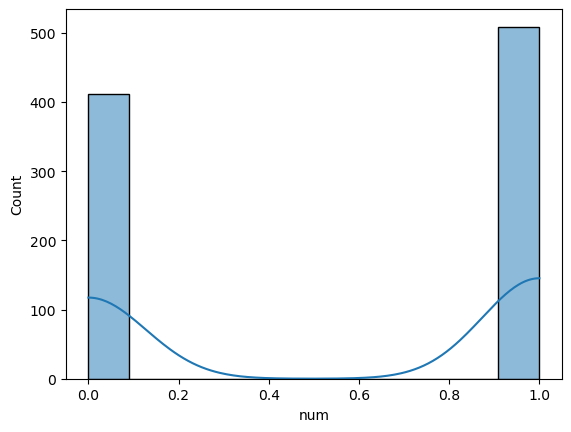

In [84]:
sns.histplot(df_cleaned['num'],kde=True)

In [85]:
df_cleaned['dataset'].value_counts()

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

In [86]:
df_cleaned.drop(columns=['dataset','id'],axis=1,inplace=True)

In [87]:
df_cleaned

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,1
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,Female,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,62,Male,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,55,Male,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,1
918,58,Male,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


In [88]:
df_cleaned.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')

In [89]:
df_cleaned.rename({'age':'Age','sex':'Sex','cp':'Chest_Pain_Type','trestbps':'Resting_Blood_Pressure','chol':'Cholesterol_Level','fbs':'Fasting_Blood_Sugar','restecg':'Resting_ECG_Result','thalch':'Maxaimum_Heart_Rate','exang':'Exercise_Induced_Angina','oldpeak':'ST_Depression','slope':'ST_Segment_Slope','ca':'Major_Blood_Vessels','thal':'Thalassemia_Category','num':'Heart_Disease'},axis=1,inplace=True)

In [90]:
df_cleaned

,Age,Sex,Chest_Pain_Type,Resting_Blood_Pressure,Cholesterol_Level,Fasting_Blood_Sugar,Resting_ECG_Result,Maxaimum_Heart_Rate,Exercise_Induced_Angina,ST_Depression,ST_Segment_Slope,Major_Blood_Vessels,Thalassemia_Category,Heart_Disease
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,1
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,Female,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,62,Male,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,55,Male,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,1
918,58,Male,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


In [91]:
df_cleaned

,Age,Sex,Chest_Pain_Type,Resting_Blood_Pressure,Cholesterol_Level,Fasting_Blood_Sugar,Resting_ECG_Result,Maxaimum_Heart_Rate,Exercise_Induced_Angina,ST_Depression,ST_Segment_Slope,Major_Blood_Vessels,Thalassemia_Category,Heart_Disease
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,1
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,Female,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,62,Male,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,55,Male,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,1
918,58,Male,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


In [92]:
columns=list(df_cleaned)

In [93]:
df_cleaned.describe()

,Age,Resting_Blood_Pressure,Cholesterol_Level,Maxaimum_Heart_Rate,ST_Depression,Major_Blood_Vessels,Heart_Disease
count,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.553261
std,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,0.497426
min,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,1.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,1.000000


In [94]:
columns

['Age',
 'Sex',
 'Chest_Pain_Type',
 'Resting_Blood_Pressure',
 'Cholesterol_Level',
 'Fasting_Blood_Sugar',
 'Resting_ECG_Result',
 'Maxaimum_Heart_Rate',
 'Exercise_Induced_Angina',
 'ST_Depression',
 'ST_Segment_Slope',
 'Major_Blood_Vessels',
 'Thalassemia_Category',
 'Heart_Disease']

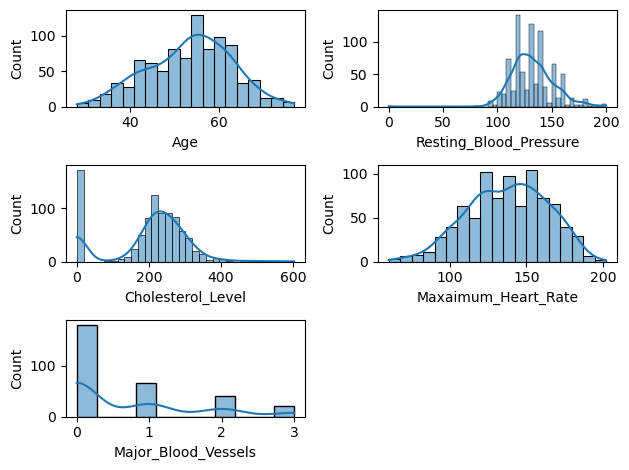

In [95]:
def plotting(var,num):
  plt.subplot(3,2,num)
  sns.histplot(df_cleaned[var],kde=True)

plotting('Age',1)
plotting('Resting_Blood_Pressure',2)
plotting('Cholesterol_Level',3)
plotting('Maxaimum_Heart_Rate',4)
plotting('Major_Blood_Vessels',5)
plt.tight_layout()

<Axes: xlabel='Heart_Disease'>

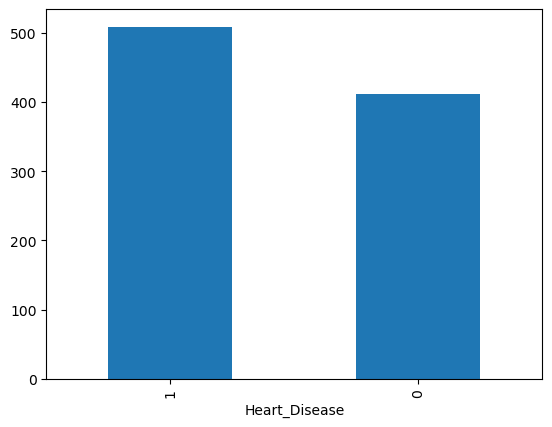

In [96]:
df_cleaned['Heart_Disease'].value_counts().plot(kind='bar')

In [97]:
df_cleaned['Resting_Blood_Pressure'].value_counts()

Resting_Blood_Pressure
120.0    131
130.0    115
140.0    102
110.0     59
150.0     56
        ... 
92.0       1
185.0      1
0.0        1
96.0       1
127.0      1
Name: count, Length: 61, dtype: int64

In [98]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      920 non-null    int64  
 1   Sex                      920 non-null    object 
 2   Chest_Pain_Type          920 non-null    object 
 3   Resting_Blood_Pressure   861 non-null    float64
 4   Cholesterol_Level        890 non-null    float64
 5   Fasting_Blood_Sugar      830 non-null    object 
 6   Resting_ECG_Result       918 non-null    object 
 7   Maxaimum_Heart_Rate      865 non-null    float64
 8   Exercise_Induced_Angina  865 non-null    object 
 9   ST_Depression            858 non-null    float64
 10  ST_Segment_Slope         611 non-null    object 
 11  Major_Blood_Vessels      309 non-null    float64
 12  Thalassemia_Category     434 non-null    object 
 13  Heart_Disease            920 non-null    int64  
dtypes: float64(5), int64(2), o

In [99]:
df_cleaned.describe()

,Age,Resting_Blood_Pressure,Cholesterol_Level,Maxaimum_Heart_Rate,ST_Depression,Major_Blood_Vessels,Heart_Disease
count,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.553261
std,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,0.497426
min,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,1.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,1.000000


In [100]:
df_cleaned['Major_Blood_Vessels'].value_counts()

Major_Blood_Vessels
0.0    181
1.0     67
2.0     41
3.0     20
Name: count, dtype: int64

In [101]:
df_cleaned['ST_Depression'].value_counts()

ST_Depression
 0.0    370
 1.0     83
 2.0     76
 1.5     48
 3.0     28
 0.5     19
 1.2     17
 2.5     16
 0.8     15
 1.4     15
 0.6     14
 0.2     14
 1.6     14
 1.8     12
 0.4     10
 0.1      9
 4.0      8
 2.6      7
 2.8      7
 2.2      5
 1.3      5
 0.3      5
 0.7      5
 1.9      5
 1.1      4
 3.6      4
 2.4      4
 0.9      4
 3.4      3
-0.5      2
 3.2      2
 2.3      2
 3.5      2
 1.7      2
-1.0      2
 4.2      2
 2.1      2
 3.1      1
 2.9      1
 6.2      1
 5.6      1
 3.8      1
-1.1      1
 4.4      1
 5.0      1
-2.6      1
-0.1      1
-1.5      1
-2.0      1
-0.7      1
-0.8      1
-0.9      1
 3.7      1
Name: count, dtype: int64

<Axes: xlabel='ST_Depression', ylabel='Count'>

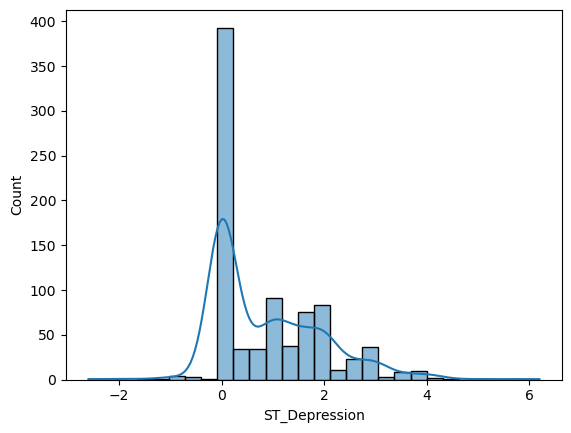

In [102]:
sns.histplot(df_cleaned['ST_Depression'],kde=True)

In [103]:
df_cleaned['Thalassemia_Category'].value_counts(dropna=False)

Thalassemia_Category
NaN                  486
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64

<Axes: >

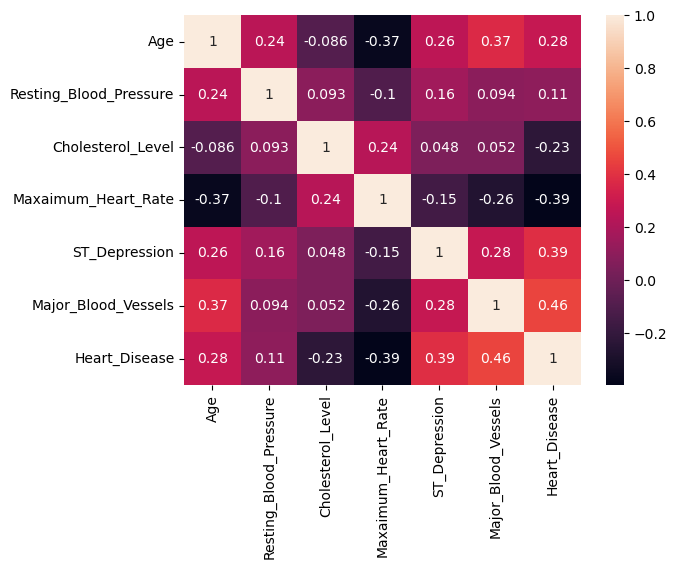

In [104]:
sns.heatmap(df_cleaned.corr(numeric_only=True), annot=True)

In [105]:
print(df_cleaned['Thalassemia_Category'].isna().sum())

486


In [106]:
print(df_cleaned['Thalassemia_Category'].value_counts(dropna=False))
df_cleaned.drop('Thalassemia_Category',axis=1,inplace=True)

Thalassemia_Category
NaN                  486
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64


In [107]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      920 non-null    int64  
 1   Sex                      920 non-null    object 
 2   Chest_Pain_Type          920 non-null    object 
 3   Resting_Blood_Pressure   861 non-null    float64
 4   Cholesterol_Level        890 non-null    float64
 5   Fasting_Blood_Sugar      830 non-null    object 
 6   Resting_ECG_Result       918 non-null    object 
 7   Maxaimum_Heart_Rate      865 non-null    float64
 8   Exercise_Induced_Angina  865 non-null    object 
 9   ST_Depression            858 non-null    float64
 10  ST_Segment_Slope         611 non-null    object 
 11  Major_Blood_Vessels      309 non-null    float64
 12  Heart_Disease            920 non-null    int64  
dtypes: float64(5), int64(2), object(6)
memory usage: 93.6+ KB


In [108]:
Cholesterol_Level_Mean=df_cleaned.loc[df_cleaned['Cholesterol_Level']!=0,'Cholesterol_Level'].mean()

In [109]:
Cholesterol_Level_Mean

np.float64(246.83286908077994)

In [110]:
df_cleaned['Cholesterol_Level']=df_cleaned['Cholesterol_Level'].replace(0,Cholesterol_Level_Mean)
df_cleaned['Cholesterol_Level']=df_cleaned['Cholesterol_Level'].round(2)

In [111]:
Resting_Blood_Pressure_Mean=df_cleaned.loc[df_cleaned['Resting_Blood_Pressure']!=0,'Resting_Blood_Pressure'].mean()

In [112]:
df_cleaned['Resting_Blood_Pressure']=df_cleaned['Resting_Blood_Pressure'].replace(0,Resting_Blood_Pressure_Mean)
df_cleaned['Resting_Blood_Pressure']=df_cleaned['Resting_Blood_Pressure'].round(2)

<Axes: xlabel='Sex', ylabel='count'>

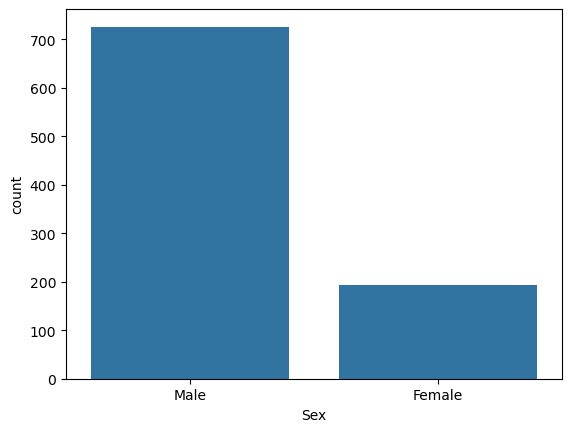

In [113]:
sns.countplot(x=df_cleaned['Sex'])

In [114]:
df_cleaned

,Age,Sex,Chest_Pain_Type,Resting_Blood_Pressure,Cholesterol_Level,Fasting_Blood_Sugar,Resting_ECG_Result,Maxaimum_Heart_Rate,Exercise_Induced_Angina,ST_Depression,ST_Segment_Slope,Major_Blood_Vessels,Heart_Disease
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,1
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,Female,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,1
916,62,Male,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,0
917,55,Male,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,1
918,58,Male,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,0


<Axes: xlabel='Chest_Pain_Type', ylabel='count'>

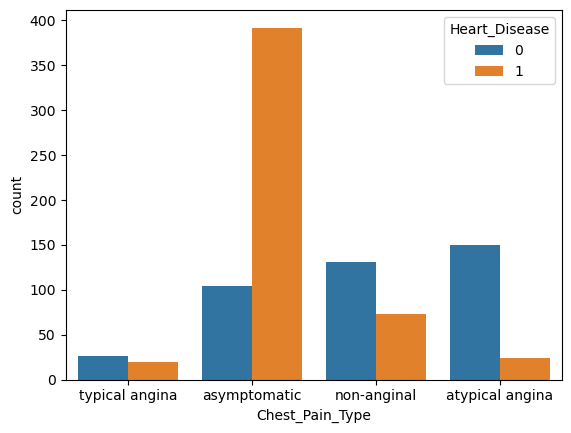

In [115]:
sns.countplot(x=df_cleaned['Chest_Pain_Type'],hue=df_cleaned['Heart_Disease'])

In [116]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      920 non-null    int64  
 1   Sex                      920 non-null    object 
 2   Chest_Pain_Type          920 non-null    object 
 3   Resting_Blood_Pressure   861 non-null    float64
 4   Cholesterol_Level        890 non-null    float64
 5   Fasting_Blood_Sugar      830 non-null    object 
 6   Resting_ECG_Result       918 non-null    object 
 7   Maxaimum_Heart_Rate      865 non-null    float64
 8   Exercise_Induced_Angina  865 non-null    object 
 9   ST_Depression            858 non-null    float64
 10  ST_Segment_Slope         611 non-null    object 
 11  Major_Blood_Vessels      309 non-null    float64
 12  Heart_Disease            920 non-null    int64  
dtypes: float64(5), int64(2), object(6)
memory usage: 93.6+ KB


In [117]:
columns=list(df_cleaned.columns)
columns

['Age',
 'Sex',
 'Chest_Pain_Type',
 'Resting_Blood_Pressure',
 'Cholesterol_Level',
 'Fasting_Blood_Sugar',
 'Resting_ECG_Result',
 'Maxaimum_Heart_Rate',
 'Exercise_Induced_Angina',
 'ST_Depression',
 'ST_Segment_Slope',
 'Major_Blood_Vessels',
 'Heart_Disease']

In [118]:
def showNull(a):
    print('Nan in '+a+' :'+str(df_cleaned[a].isna().sum()))
for c in columns:
    showNull(c)

Nan in Age :0
Nan in Sex :0
Nan in Chest_Pain_Type :0
Nan in Resting_Blood_Pressure :59
Nan in Cholesterol_Level :30
Nan in Fasting_Blood_Sugar :90
Nan in Resting_ECG_Result :2
Nan in Maxaimum_Heart_Rate :55
Nan in Exercise_Induced_Angina :55
Nan in ST_Depression :62
Nan in ST_Segment_Slope :309
Nan in Major_Blood_Vessels :611
Nan in Heart_Disease :0


In [119]:
df_cleaned.describe()

,Age,Resting_Blood_Pressure,Cholesterol_Level,Maxaimum_Heart_Rate,ST_Depression,Major_Blood_Vessels,Heart_Disease
count,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,53.510870,132.286051,246.832315,137.545665,0.878788,0.676375,0.553261
std,9.424685,18.525395,52.561218,25.926276,1.091226,0.935653,0.497426
min,28.000000,80.000000,85.000000,60.000000,-2.600000,0.000000,0.000000
25%,47.000000,120.000000,216.000000,120.000000,0.000000,0.000000,0.000000
50%,54.000000,130.000000,246.830000,140.000000,0.500000,0.000000,1.000000
75%,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,1.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,1.000000


In [120]:
df_cleaned.fillna(0,inplace=True)

In [121]:
Fasting_Blood_Sugar_Mode1=df_cleaned.loc[df_cleaned['Fasting_Blood_Sugar']!=0,'Fasting_Blood_Sugar'].mode()
type(Fasting_Blood_Sugar_Mode1)

pandas.core.series.Series

In [122]:
df_cleaned['Resting_Blood_Pressure']=df_cleaned['Resting_Blood_Pressure'].replace(0,Resting_Blood_Pressure_Mean)
df_cleaned['Resting_Blood_Pressure']=df_cleaned['Resting_Blood_Pressure'].round(2)

df_cleaned['Cholesterol_Level']=df_cleaned['Cholesterol_Level'].replace(0,Cholesterol_Level_Mean)
df_cleaned['Cholesterol_Level']=df_cleaned['Cholesterol_Level'].round(2)

Fasting_Blood_Sugar_Mode=df_cleaned.loc[df_cleaned['Fasting_Blood_Sugar']!=0,'Fasting_Blood_Sugar'].mode()
df_cleaned['Fasting_Blood_Sugar']=df_cleaned['Fasting_Blood_Sugar'].replace(0,Fasting_Blood_Sugar_Mode[0])
df_cleaned['Fasting_Blood_Sugar']=df_cleaned['Fasting_Blood_Sugar']

Resting_ECG_Result_Mode=df_cleaned.loc[df_cleaned['Resting_ECG_Result']!=0,'Resting_ECG_Result'].mode()
df_cleaned['Resting_ECG_Result']=df_cleaned['Resting_ECG_Result'].replace(0,Resting_ECG_Result_Mode[0])
df_cleaned['Resting_ECG_Result']=df_cleaned['Resting_ECG_Result']

Maxaimum_Heart_Rate_Mean=df_cleaned.loc[df_cleaned['Maxaimum_Heart_Rate']!=0,'Maxaimum_Heart_Rate'].mean()
df_cleaned['Maxaimum_Heart_Rate']=df_cleaned['Maxaimum_Heart_Rate'].replace(0,Maxaimum_Heart_Rate_Mean)
df_cleaned['Maxaimum_Heart_Rate']=df_cleaned['Maxaimum_Heart_Rate'].round(2)

Exercise_Induced_Angina_Mode=df_cleaned.loc[df_cleaned['Exercise_Induced_Angina']!=0,'Exercise_Induced_Angina'].mode()
df_cleaned['Exercise_Induced_Angina']=df_cleaned['Exercise_Induced_Angina'].replace(0,Exercise_Induced_Angina_Mode[0])
df_cleaned['Exercise_Induced_Angina']=df_cleaned['Exercise_Induced_Angina']

ST_Depression_Mean=df_cleaned.loc[df_cleaned['ST_Depression']!=0,'ST_Depression'].mean()
df_cleaned['ST_Depression']=df_cleaned['ST_Depression'].replace(0,ST_Depression_Mean)
df_cleaned['ST_Depression']=df_cleaned['ST_Depression'].round(1)

ST_Segment_Slope_Mode=df_cleaned.loc[df_cleaned['ST_Segment_Slope']!=0,'ST_Segment_Slope'].mode()
df_cleaned['ST_Segment_Slope']=df_cleaned['ST_Segment_Slope'].replace(0,ST_Segment_Slope_Mode[0])
df_cleaned['ST_Segment_Slope']=df_cleaned['ST_Segment_Slope']

Major_Blood_Vessels_Mode=df_cleaned.loc[df_cleaned['Major_Blood_Vessels']!=0,'Major_Blood_Vessels'].mode()
df_cleaned['Major_Blood_Vessels']=df_cleaned['Major_Blood_Vessels'].replace(0,Major_Blood_Vessels_Mode[0])
df_cleaned['Major_Blood_Vessels']=df_cleaned['Major_Blood_Vessels']

C:\Users\USER\AppData\Local\Temp\ipykernel_1684\361359047.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_cleaned['Fasting_Blood_Sugar']=df_cleaned['Fasting_Blood_Sugar'].replace(0,Fasting_Blood_Sugar_Mode[0])
C:\Users\USER\AppData\Local\Temp\ipykernel_1684\361359047.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_cleaned['Exercise_Induced_Angina']=df_cleaned['Exercise_Induced_Angina'].replace(0,Exercise_Induced_Angina_Mode[0])


In [123]:
df_cleaned['ST_Depression'].value_counts(dropna=False)

ST_Depression
 1.5    480
 1.0     83
 2.0     76
 3.0     28
 0.5     19
 1.2     17
 2.5     16
 0.8     15
 1.4     15
 0.6     14
 0.2     14
 1.6     14
 1.8     12
 0.4     10
 0.1      9
 4.0      8
 2.6      7
 2.8      7
 2.2      5
 1.3      5
 0.3      5
 0.7      5
 1.9      5
 1.1      4
 3.6      4
 2.4      4
 0.9      4
 3.4      3
-0.5      2
 3.2      2
 2.3      2
 3.5      2
 1.7      2
-1.0      2
 4.2      2
 2.1      2
 3.1      1
 2.9      1
 6.2      1
 5.6      1
 3.8      1
-1.1      1
 4.4      1
 5.0      1
-2.6      1
-0.1      1
-1.5      1
-2.0      1
-0.7      1
-0.8      1
-0.9      1
 3.7      1
Name: count, dtype: int64

In [124]:
# df_cleaned['Major_Blood_Vessels'].value_counts(dropna=False)
df_cleaned['ST_Segment_Slope'].mode()

0    flat
Name: ST_Segment_Slope, dtype: object

In [125]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      920 non-null    int64  
 1   Sex                      920 non-null    object 
 2   Chest_Pain_Type          920 non-null    object 
 3   Resting_Blood_Pressure   920 non-null    float64
 4   Cholesterol_Level        920 non-null    float64
 5   Fasting_Blood_Sugar      920 non-null    bool   
 6   Resting_ECG_Result       920 non-null    object 
 7   Maxaimum_Heart_Rate      920 non-null    float64
 8   Exercise_Induced_Angina  920 non-null    bool   
 9   ST_Depression            920 non-null    float64
 10  ST_Segment_Slope         920 non-null    object 
 11  Major_Blood_Vessels      920 non-null    float64
 12  Heart_Disease            920 non-null    int64  
dtypes: bool(2), float64(5), int64(2), object(4)
memory usage: 81.0+ KB


In [126]:
df_cleaned['Resting_Blood_Pressure'].isna().sum()

np.int64(0)

In [127]:
df_cleaned['Resting_Blood_Pressure'].value_counts(dropna=False)

Resting_Blood_Pressure
120.00    131
130.00    115
140.00    102
132.29     60
110.00     59
         ... 
113.00      1
80.00       1
185.00      1
96.00       1
127.00      1
Name: count, Length: 61, dtype: int64

In [128]:
df_cleaned

,Age,Sex,Chest_Pain_Type,Resting_Blood_Pressure,Cholesterol_Level,Fasting_Blood_Sugar,Resting_ECG_Result,Maxaimum_Heart_Rate,Exercise_Induced_Angina,ST_Depression,ST_Segment_Slope,Major_Blood_Vessels,Heart_Disease
0,63,Male,typical angina,145.00,233.0,True,lv hypertrophy,150.00,True,2.3,downsloping,1.0,0
1,67,Male,asymptomatic,160.00,286.0,True,lv hypertrophy,108.00,True,1.5,flat,3.0,1
2,67,Male,asymptomatic,120.00,229.0,True,lv hypertrophy,129.00,True,2.6,flat,2.0,1
3,37,Male,non-anginal,130.00,250.0,True,normal,187.00,True,3.5,downsloping,1.0,0
4,41,Female,atypical angina,130.00,204.0,True,lv hypertrophy,172.00,True,1.4,upsloping,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,Female,asymptomatic,127.00,333.0,True,st-t abnormality,154.00,True,1.5,flat,1.0,1
916,62,Male,typical angina,132.29,139.0,True,st-t abnormality,137.55,True,1.5,flat,1.0,0
917,55,Male,asymptomatic,122.00,223.0,True,st-t abnormality,100.00,True,1.5,flat,1.0,1
918,58,Male,asymptomatic,132.29,385.0,True,lv hypertrophy,137.55,True,1.5,flat,1.0,0


In [129]:
df_cleaned.info(

)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      920 non-null    int64  
 1   Sex                      920 non-null    object 
 2   Chest_Pain_Type          920 non-null    object 
 3   Resting_Blood_Pressure   920 non-null    float64
 4   Cholesterol_Level        920 non-null    float64
 5   Fasting_Blood_Sugar      920 non-null    bool   
 6   Resting_ECG_Result       920 non-null    object 
 7   Maxaimum_Heart_Rate      920 non-null    float64
 8   Exercise_Induced_Angina  920 non-null    bool   
 9   ST_Depression            920 non-null    float64
 10  ST_Segment_Slope         920 non-null    object 
 11  Major_Blood_Vessels      920 non-null    float64
 12  Heart_Disease            920 non-null    int64  
dtypes: bool(2), float64(5), int64(2), object(4)
memory usage: 81.0+ KB


In [130]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      920 non-null    int64  
 1   Sex                      920 non-null    object 
 2   Chest_Pain_Type          920 non-null    object 
 3   Resting_Blood_Pressure   920 non-null    float64
 4   Cholesterol_Level        920 non-null    float64
 5   Fasting_Blood_Sugar      920 non-null    bool   
 6   Resting_ECG_Result       920 non-null    object 
 7   Maxaimum_Heart_Rate      920 non-null    float64
 8   Exercise_Induced_Angina  920 non-null    bool   
 9   ST_Depression            920 non-null    float64
 10  ST_Segment_Slope         920 non-null    object 
 11  Major_Blood_Vessels      920 non-null    float64
 12  Heart_Disease            920 non-null    int64  
dtypes: bool(2), float64(5), int64(2), object(4)
memory usage: 81.0+ KB


In [131]:
df_cleaned['Cholesterol_Level'].value_counts(dropna=False)

Cholesterol_Level
246.83    202
220.00     10
254.00     10
204.00      9
219.00      9
         ... 
165.00      1
337.00      1
333.00      1
139.00      1
385.00      1
Name: count, Length: 217, dtype: int64

In [132]:
df_cleaned['Resting_Blood_Pressure'].value_counts(dropna=False)

Resting_Blood_Pressure
120.00    131
130.00    115
140.00    102
132.29     60
110.00     59
         ... 
113.00      1
80.00       1
185.00      1
96.00       1
127.00      1
Name: count, Length: 61, dtype: int64

In [133]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      920 non-null    int64  
 1   Sex                      920 non-null    object 
 2   Chest_Pain_Type          920 non-null    object 
 3   Resting_Blood_Pressure   920 non-null    float64
 4   Cholesterol_Level        920 non-null    float64
 5   Fasting_Blood_Sugar      920 non-null    bool   
 6   Resting_ECG_Result       920 non-null    object 
 7   Maxaimum_Heart_Rate      920 non-null    float64
 8   Exercise_Induced_Angina  920 non-null    bool   
 9   ST_Depression            920 non-null    float64
 10  ST_Segment_Slope         920 non-null    object 
 11  Major_Blood_Vessels      920 non-null    float64
 12  Heart_Disease            920 non-null    int64  
dtypes: bool(2), float64(5), int64(2), object(4)
memory usage: 81.0+ KB


In [134]:
df_cleaned['Resting_Blood_Pressure']

0      145.00
1      160.00
2      120.00
3      130.00
4      130.00
        ...  
915    127.00
916    132.29
917    122.00
918    132.29
919    120.00
Name: Resting_Blood_Pressure, Length: 920, dtype: float64

In [139]:
df_encoded = pd.get_dummies(df_cleaned,drop_first=True)

In [140]:
df_encoded.head()

,Age,Resting_Blood_Pressure,Cholesterol_Level,Fasting_Blood_Sugar,Maxaimum_Heart_Rate,Exercise_Induced_Angina,ST_Depression,Major_Blood_Vessels,Heart_Disease,Sex_Male,Chest_Pain_Type_atypical angina,Chest_Pain_Type_non-anginal,Chest_Pain_Type_typical angina,Resting_ECG_Result_normal,Resting_ECG_Result_st-t abnormality,ST_Segment_Slope_flat,ST_Segment_Slope_upsloping
0,63,145.0,233.0,True,150.0,True,2.3,1.0,0,True,False,False,True,False,False,False,False
1,67,160.0,286.0,True,108.0,True,1.5,3.0,1,True,False,False,False,False,False,True,False
2,67,120.0,229.0,True,129.0,True,2.6,2.0,1,True,False,False,False,False,False,True,False
3,37,130.0,250.0,True,187.0,True,3.5,1.0,0,True,False,True,False,True,False,False,False
4,41,130.0,204.0,True,172.0,True,1.4,1.0,0,False,True,False,False,False,False,False,True


In [141]:
df_encoded = df_encoded.astype(int)

In [142]:
df_encoded.head()

,Age,Resting_Blood_Pressure,Cholesterol_Level,Fasting_Blood_Sugar,Maxaimum_Heart_Rate,Exercise_Induced_Angina,ST_Depression,Major_Blood_Vessels,Heart_Disease,Sex_Male,Chest_Pain_Type_atypical angina,Chest_Pain_Type_non-anginal,Chest_Pain_Type_typical angina,Resting_ECG_Result_normal,Resting_ECG_Result_st-t abnormality,ST_Segment_Slope_flat,ST_Segment_Slope_upsloping
0,63,145,233,1,150,1,2,1,0,1,0,0,1,0,0,0,0
1,67,160,286,1,108,1,1,3,1,1,0,0,0,0,0,1,0
2,67,120,229,1,129,1,2,2,1,1,0,0,0,0,0,1,0
3,37,130,250,1,187,1,3,1,0,1,0,1,0,1,0,0,0
4,41,130,204,1,172,1,1,1,0,0,1,0,0,0,0,0,1


In [143]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,f1_score,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [146]:
X=df_encoded.drop('Heart_Disease',axis=1)
y=df_encoded['Heart_Disease']

In [147]:
 X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [148]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

In [149]:
models={
    'Logistic Regression':LogisticRegression(),
    'KNN':KNeighborsClassifier(),
    'Naive Bayes':GaussianNB(),
    'Decision tree':DecisionTreeClassifier(),
    'SVM':SVC()
}

In [151]:
result=[]
for name,model in models.items():
    model.fit(X_train_scaled,y_train)
    y_pred=model.predict(X_test_scaled)
    acc=accuracy_score(y_test,y_pred)
    f1=f1_score(y_test,y_pred)
    result.append(
        {
            'model':name,
            'Accuracy':round(acc,4),
            'f1 score':round(f1,4)
        }
    )

In [152]:
result

[{'model': 'Logistic Regression', 'Accuracy': 0.8098, 'f1 score': 0.8372},
 {'model': 'KNN', 'Accuracy': 0.7826, 'f1 score': 0.8077},
 {'model': 'Naive Bayes', 'Accuracy': 0.7717, 'f1 score': 0.7941},
 {'model': 'Decision tree', 'Accuracy': 0.6957, 'f1 score': 0.7228},
 {'model': 'SVM', 'Accuracy': 0.7935, 'f1 score': 0.8224}]

In [153]:
import joblib
joblib.dump(models['Logistic Regression'],'Logistic Regression.pkl')
joblib.dump(scaler,'scaler.pkl')
joblib.dump(X.columns.tolist(),'columns.pkl')

['columns.pkl']